# ¿Adelantará BYD a Tesla en eléctricos puros en España?

## Objetivo

Quiero estimar qué marca cerrará 2026 con más matriculaciones de turismos eléctricos de batería en España. Trabajo con los microdatos mensuales de la DGT entre enero de 2023 y septiembre de 2026. Comparo una referencia estacional con cuatro modelos de tendencia y periodicidad, separo validación y prueba temporal, y solo acepto un modelo más complejo si supera a la referencia fuera de muestra.

La unidad es un **turismo nuevo** (`COD_TIPO = 40`, `COD_PROPULSION_ITV = 2`, `IND_NUEVO_USADO = N`). No mezclo híbridos enchufables. La fecha de corte es el 30 de septiembre de 2026.

## 1. Fuentes y preparación

Descargo un ZIP por mes desde la [DGT](https://www.dgt.es/menusecundario/dgt-en-cifras/dgt-en-cifras-resultados/dgt-en-cifras-detalle/Microdatos-de-Matriculaciones-de-Vehiculos-mensual/) y sigo su [diseño de registro](https://www.dgt.es/export/sites/web-DGT/.galleries/downloads/dgt-en-cifras/matraba/MATRICULACIONES_MATRABA.pdf). `preparar_datos.py` lee los ficheros de ancho fijo sin descomprimirlos, descarta la cabecera y conserva únicamente los campos necesarios. El CSV mensual incluido permite reproducir el análisis sin descargar cientos de megabytes.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

AZUL = "#446ddf"
ROJO = "#d85a30"
GRIS = "#6b7280"
plt.style.use("seaborn-v0_8-whitegrid")

# busco los archivos tanto al ejecutar desde la raíz como desde la carpeta del cuaderno
RAIZ = Path.cwd()
if not (RAIZ / "data" / "processed" / "matriculaciones_mensuales.csv").exists():
    RAIZ = RAIZ / "work" / "byd_tesla_electricos"
sys.path.insert(0, str(RAIZ))

from evaluar_modelos import MODELOS, smape

ruta_datos = RAIZ / "data" / "processed" / "matriculaciones_mensuales.csv"
datos = pd.read_csv(ruta_datos, parse_dates=["mes"])
tabla = datos.pivot(index="mes", columns="marca", values="matriculaciones").sort_index()
tabla.tail()

marca,BYD,Tesla
mes,,
2026-05-01,1648,1691
2026-06-01,1971,2784
2026-07-01,1524,131
2026-08-01,1357,304
2026-09-01,2290,3737


### Controles de calidad

Compruebo que existen los 45 meses consecutivos, que cada mes contiene las dos marcas y que no hay valores negativos ni ausentes. También comparo el acumulado con las cifras publicadas por Ideauto/Anfac: las diferencias son mínimas y compatibles con cierres y revisiones de fuentes distintas.

In [2]:
esperados = pd.date_range("2023-01-01", "2026-09-01", freq="MS")
assert tabla.index.equals(esperados)
assert set(tabla.columns) == {"BYD", "Tesla"}
assert tabla.notna().all().all()
assert (tabla >= 0).all().all()

acumulado_2026 = tabla.loc[tabla.index.year == 2026].sum().astype(int)
print("Meses:", len(tabla))
print("Acumulado enero-septiembre de 2026:")
display(acumulado_2026.to_frame("matriculaciones"))

Meses: 45
Acumulado enero-septiembre de 2026:


,matriculaciones
marca,
BYD,14227
Tesla,13481


## 2. La carrera mensual

Tesla entrega de forma muy irregular y suele concentrar coches al final de trimestre. BYD tiene una trayectoria más continua desde su llegada en 2023. Por eso una comparación basada solo en septiembre exageraría la distancia mensual de Tesla, aunque BYD conserve la ventaja anual.

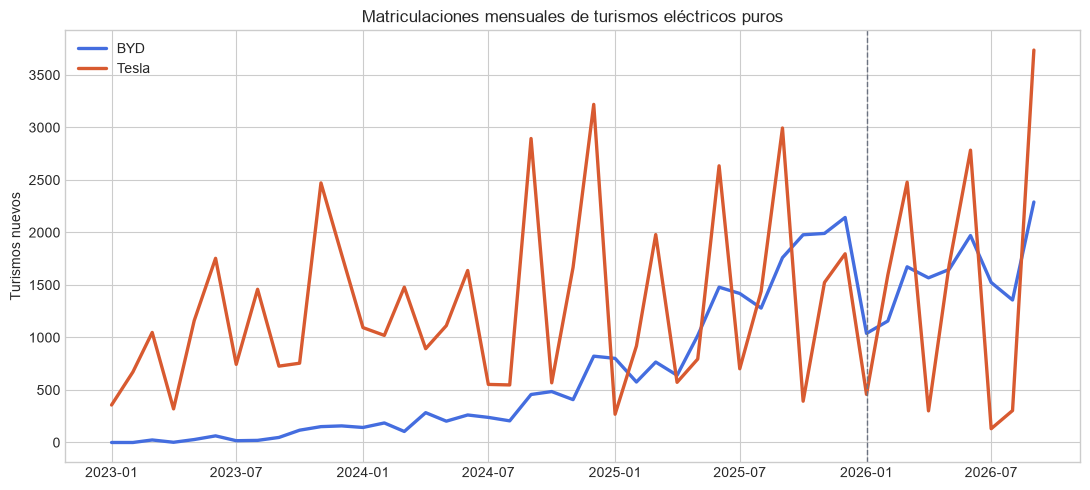

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(tabla.index, tabla["BYD"], color=AZUL, linewidth=2.4, label="BYD")
ax.plot(tabla.index, tabla["Tesla"], color=ROJO, linewidth=2.4, label="Tesla")
ax.axvline(pd.Timestamp("2026-01-01"), color=GRIS, linestyle="--", linewidth=1)
ax.set(title="Matriculaciones mensuales de turismos eléctricos puros", ylabel="Turismos nuevos")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 3. Diseño de la predicción

Uso 2023-2024 para arrancar. En 2025 valido cinco alternativas mediante cuatro pronósticos trimestrales encadenados. El mejor modelo de esa fase pasa después un examen separado con nueve meses de 2026, también en bloques trimestrales. La métrica principal es el error absoluto medio (MAE), fácil de leer como coches de diferencia; añado sMAPE para comparar escalas.

La referencia estacional repite el mismo mes del año anterior. Las alternativas aplican crecimiento reciente o regresiones regularizadas con tendencia, ciclo anual y patrón trimestral. No mezclo meses futuros en el entrenamiento de cada corte.

In [4]:
fases = {"validación 2025": [24, 27, 30, 33], "prueba 2026": [36, 39, 42]}
filas = []
residuos_test = {marca: {modelo: [] for modelo in MODELOS} for marca in tabla.columns}

for marca in tabla.columns:
    serie = tabla[marca].to_numpy(dtype=float)
    for nombre, funcion in MODELOS.items():
        for fase, cortes in fases.items():
            reales, predichos = [], []
            for corte in cortes:
                real = serie[corte:corte + 3]
                pred = funcion(serie[:corte], 3)
                reales.extend(real)
                predichos.extend(pred)
                if fase == "prueba 2026":
                    residuos_test[marca][nombre].extend((real - pred).tolist())
            reales = np.asarray(reales)
            predichos = np.asarray(predichos)
            filas.append({
                "marca": marca,
                "modelo": nombre,
                "fase": fase,
                "MAE": np.mean(np.abs(reales - predichos)),
                "sMAPE": smape(reales, predichos),
                "n": len(reales),
            })

metricas = pd.DataFrame(filas)
display(metricas.round(1).sort_values(["marca", "fase", "MAE"]))

,marca,modelo,fase,MAE,sMAPE,n
5,BYD,regresion_periodica,prueba 2026,261.1,17.0,9
7,BYD,regresion_periodica_24m,prueba 2026,302.3,19.0,9
1,BYD,estacional,prueba 2026,498.6,40.7,9
3,BYD,estacional_crecimiento,prueba 2026,617.5,31.2,9
9,BYD,regresion_logaritmica_24m,prueba 2026,696.4,36.3,9
8,BYD,regresion_logaritmica_24m,validación 2025,348.4,30.7,12
6,BYD,regresion_periodica_24m,validación 2025,512.8,46.6,12
4,BYD,regresion_periodica,validación 2025,572.2,51.9,12
2,BYD,estacional_crecimiento,validación 2025,608.5,64.0,12
0,BYD,estacional,validación 2025,1004.3,124.2,12


## 4. El modelo complejo no se gana el puesto

Elijo el candidato con menor MAE en la validación de 2025, antes de mirar la prueba. Después comparo ese candidato con la referencia estacional en 2026. En ambas marcas, el candidato falla el examen: para BYD queda en 696 coches de error mensual frente a 499 de la referencia; para Tesla, en 589 frente a 570. Mantengo la referencia. Es una conclusión menos vistosa, pero evita premiar un modelo que aprendió un ritmo de crecimiento que ya no se repite.

In [5]:
validacion = metricas[metricas["fase"] == "validación 2025"]
candidatos = validacion.loc[validacion.groupby("marca")["MAE"].idxmin()].set_index("marca")["modelo"].to_dict()
finales = {}

for marca in tabla.columns:
    candidato = candidatos[marca]
    mae_candidato = metricas.query("marca == @marca and modelo == @candidato and fase == 'prueba 2026'")["MAE"].iloc[0]
    mae_base = metricas.query("marca == @marca and modelo == 'estacional' and fase == 'prueba 2026'")["MAE"].iloc[0]
    finales[marca] = candidato if mae_candidato < mae_base else "estacional"

pd.DataFrame({"candidato elegido en validación": candidatos, "modelo final": finales})

,candidato elegido en validación,modelo final
BYD,regresion_logaritmica_24m,estacional
Tesla,regresion_periodica_24m,estacional


## 5. Pronóstico de octubre a diciembre

La referencia toma octubre, noviembre y diciembre de 2025 como estimación de los mismos meses de 2026. Sumo esos tres meses al acumulado real hasta septiembre. El resultado central es 20.339 BYD y 17.195 Tesla: una ventaja de 3.144 coches para BYD.

In [6]:
fechas_futuras = pd.date_range("2026-10-01", periods=3, freq="MS")
pronosticos = {}
for marca in tabla.columns:
    pronosticos[marca] = MODELOS[finales[marca]](tabla[marca].to_numpy(dtype=float), 3)

pronostico = pd.DataFrame(pronosticos, index=fechas_futuras).round().astype(int)
totales = acumulado_2026 + pronostico.sum()
display(pronostico)
display(totales.to_frame("total 2026 estimado"))
print("Ventaja central de BYD:", f"{int(totales['BYD'] - totales['Tesla']):,}".replace(",", "."), "coches")

,BYD,Tesla
2026-10-01,1978,393
2026-11-01,1991,1524
2026-12-01,2143,1797


,total 2026 estimado
marca,
BYD,20339
Tesla,17195


Ventaja central de BYD: 3.144 coches


## 6. Incertidumbre: 50.000 finales posibles

Reutilizo los errores de la prueba de 2026, centrados para representar variación alrededor del pronóstico, y genero 50.000 cierres de año. Este remuestreo no adivina cambios de precio, ayudas, logística o lanzamientos: solo traduce el error histórico del método a una horquilla comprensible.

In [7]:
rng = np.random.default_rng(42)
n_simulaciones = 50_000
simulados = {}

for marca in tabla.columns:
    errores = np.asarray(residuos_test[marca][finales[marca]])
    ruido = rng.choice(errores - errores.mean(), size=(n_simulaciones, 3), replace=True)
    futuro = np.clip(pronosticos[marca] + ruido, 0, None)
    simulados[marca] = acumulado_2026[marca] + futuro.sum(axis=1)

diferencia = simulados["BYD"] - simulados["Tesla"]
probabilidad = np.mean(diferencia > 0)
intervalo_80 = np.quantile(diferencia, [0.1, 0.9]).round().astype(int)

print(f"Probabilidad estimada de que BYD cierre delante: {probabilidad:.2%}")
print("Intervalo central del 80% para la ventaja de BYD:", intervalo_80.tolist())

Probabilidad estimada de que BYD cierre delante: 99.98%
Intervalo central del 80% para la ventaja de BYD: [1594, 4478]


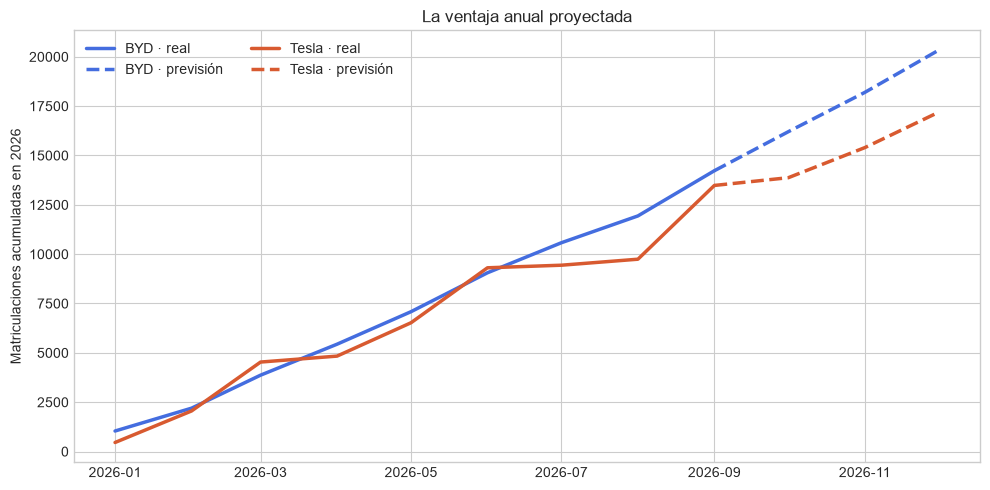

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
acumulada = tabla.loc[tabla.index.year == 2026].cumsum()
for marca, color in [("BYD", AZUL), ("Tesla", ROJO)]:
    futuro_acumulado = acumulada[marca].iloc[-1] + pronostico[marca].cumsum()
    ax.plot(acumulada.index, acumulada[marca], color=color, linewidth=2.5, label=f"{marca} · real")
    ax.plot([acumulada.index[-1], *fechas_futuras], [acumulada[marca].iloc[-1], *futuro_acumulado], color=color, linestyle="--", linewidth=2.5, label=f"{marca} · previsión")
ax.set(title="La ventaja anual proyectada", ylabel="Matriculaciones acumuladas en 2026")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

## 7. Conclusión y límites

Mi predicción es que **BYD terminará 2026 por delante de Tesla en turismos eléctricos puros matriculados en España**. La estimación central deja 20.339 frente a 17.195, y 49.988 de las 50.000 simulaciones mantienen a BYD delante. Lo expreso como **más del 99%**, no como certeza.

La cifra exacta es más frágil que el orden. Solo dispongo de 45 meses, BYD no tuvo en 2023 la implantación actual y Tesla concentra entregas al final de trimestre. Una campaña comercial, un problema logístico o un cambio en las ayudas puede romper el patrón. Además, la DGT mide matriculaciones registradas, que pueden diferir ligeramente de las entregas comerciales de Ideauto/Anfac. El análisis responde quién acabará delante si el tramo final se parece, en su estacionalidad y error, al pasado reciente.

### Archivos

- `matriculaciones_mensuales.csv`: serie agregada usada por el modelo.
- `matriculaciones_byd_tesla.csv`: registros individuales filtrados y sin bastidor.
- `control_extraccion.csv`: auditoría por fichero.
- `preparar_datos.py`: extracción reproducible desde los ZIP oficiales.
- `evaluar_modelos.py`: modelos, validación, prueba y simulación.